# 2023 — Diffusion Transformers (DiT), adaLN-Zero and Classifier-Free Guidance

**Papers:** William Peebles & Saining Xie, *"Scalable Diffusion Models with Transformers"* (DiT, 2022/ICCV 2023); Ho & Salimans, *"Classifier-Free Diffusion Guidance"* (2021); Rombach et al., *Latent Diffusion* (2022). DiTs now power Stable Diffusion 3, Flux, Sora and most video models. SD3 and Flux train them with **rectified flow** (notebook 55), as we do here.

DiT replaces the U-Net denoiser (notebook 30) with a plain **Vision Transformer over image patches** (notebook 49). Two key ingredients:
- **adaLN-Zero conditioning:** the timestep and class label produce the *scale, shift and gate* of every LayerNorm and residual branch, $x \leftarrow x + \alpha \cdot f(\gamma\,\mathrm{LN}(x) + \beta)$. The gates $\alpha$ start at **zero**, so each block starts as the identity, which makes training stable.
- **Classifier-free guidance (CFG):** train with the label randomly dropped, then at sampling time extrapolate away from the unconditional prediction, $v = v_\varnothing + w\,(v_c - v_\varnothing)$. A larger $w$ gives samples that are more class-typical but less diverse.

We train a class-conditional DiT on 8×8 digits (2×2 patches → 16 tokens).

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
dg = load_digits()
X = torch.tensor(dg.images / 16.0 * 2 - 1, dtype=torch.float32)[:, None].to(device)     # (N, 1, 8, 8) in [-1, 1]
Y = torch.tensor(dg.target, device=device)
NULL = 10                                                                                # the "no label" class for CFG

In [3]:
def modulate(x, shift, scale): return x * (1 + scale[:, None]) + shift[:, None]

class DiTBlock(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d, elementwise_affine=False), nn.LayerNorm(d, elementwise_affine=False)
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(d, 6 * d))
        nn.init.zeros_(self.ada[1].weight); nn.init.zeros_(self.ada[1].bias)            # adaLN-Zero: gates start at 0
    def forward(self, x, c):
        s1, sc1, g1, s2, sc2, g2 = self.ada(c).chunk(6, -1)
        h = modulate(self.ln1(x), s1, sc1)
        x = x + g1[:, None] * self.attn(h, h, h, need_weights=False)[0]
        return x + g2[:, None] * self.mlp(modulate(self.ln2(x), s2, sc2))

class DiT(nn.Module):
    def __init__(self, d=128, depth=4, heads=4, patch=2, img=8):
        super().__init__()
        self.p, self.n = patch, (img // patch) ** 2
        self.patchify = nn.Linear(patch * patch, d); self.pos = nn.Parameter(torch.randn(1, self.n, d) * 0.02)
        self.t_mlp = nn.Sequential(nn.Linear(64, d), nn.SiLU(), nn.Linear(d, d)); self.y_emb = nn.Embedding(11, d)
        self.blocks = nn.ModuleList([DiTBlock(d, heads) for _ in range(depth)])
        self.ln_f = nn.LayerNorm(d, elementwise_affine=False); self.ada_f = nn.Sequential(nn.SiLU(), nn.Linear(d, 2 * d))
        self.out = nn.Linear(d, patch * patch)
        for m in [self.ada_f[1], self.out]: nn.init.zeros_(m.weight); nn.init.zeros_(m.bias)
    def t_embed(self, t):
        f = torch.exp(-math.log(1000) * torch.arange(32, device=t.device) / 32); a = t[:, None] * 1000 * f
        return self.t_mlp(torch.cat([a.sin(), a.cos()], -1))
    def forward(self, x, t, y):
        B = len(x); p = self.p
        tok = x.unfold(2, p, p).unfold(3, p, p).reshape(B, -1, p * p)                 # (B, 16, 4) patches
        h = self.patchify(tok) + self.pos
        c = self.t_embed(t) + self.y_emb(y)
        for b in self.blocks: h = b(h, c)
        sh, sc = self.ada_f(c).chunk(2, -1)
        out = self.out(modulate(self.ln_f(h), sh, sc))                                 # (B, 16, 4)
        g = int(self.n ** 0.5)
        return out.view(B, g, g, p, p).permute(0, 1, 3, 2, 4).reshape(B, 1, g * p, g * p)

model = DiT().to(device)
print(f"DiT parameters: {sum(p.numel() for p in model.parameters()) / 1e3:.0f}K")

DiT parameters: 1250K


## Training: rectified flow + label dropout

In [4]:
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)
steps = 4000
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=steps, pct_start=0.05)
t0 = time.time()
for s in range(steps):
    idx = torch.randint(0, len(X), (256,), device=device)
    x1, y = X[idx], Y[idx].clone()
    y[torch.rand(len(y), device=device) < 0.1] = NULL                                  # drop the label 10% of the time
    x0 = torch.randn_like(x1); t = torch.rand(len(x1), device=device)
    xt = (1 - t)[:, None, None, None] * x0 + t[:, None, None, None] * x1
    loss = F.mse_loss(model(xt, t, y), x1 - x0)                                        # velocity regression
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    if s % 1000 == 0: print(f"step {s:4d} loss {loss.item():.4f}")
print(f"trained in {time.time() - t0:.0f}s")

step    0 loss 1.7319


step 1000 loss 0.3817


step 2000 loss 0.3451


step 3000 loss 0.3206


trained in 122s


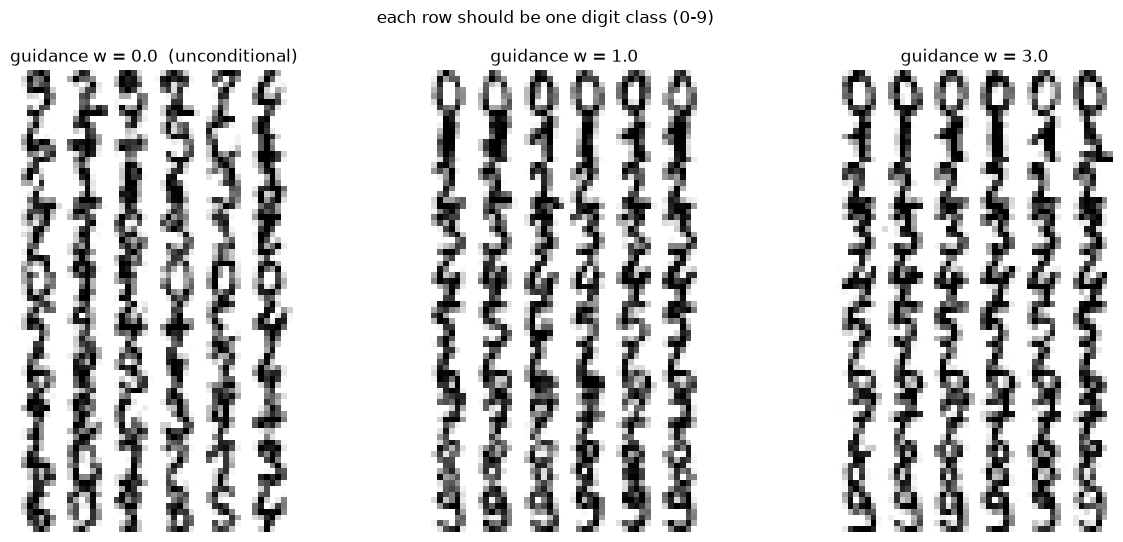

In [5]:
@torch.no_grad()
def sample(labels, w=1.0, n_steps=30):
    model.eval(); x = torch.randn(len(labels), 1, 8, 8, device=device); null = torch.full_like(labels, NULL)
    for i in range(n_steps):
        t = torch.full((len(labels),), i / n_steps, device=device)
        v_c, v_u = model(x, t, labels), model(x, t, null)
        x = x + (v_u + w * (v_c - v_u)) / n_steps                                     # classifier-free guidance
    return x.clamp(-1, 1)

labels = torch.arange(10, device=device).repeat_interleave(6)
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, w in zip(axes, [0.0, 1.0, 3.0]):
    imgs = sample(labels, w=w).cpu().view(10, 6, 8, 8).permute(0, 2, 1, 3).reshape(80, 48)
    ax.imshow(imgs, cmap="gray_r"); ax.set_title(f"guidance w = {w}" + ("  (unconditional)" if w == 0 else "")); ax.axis("off")
plt.suptitle("each row should be one digit class (0-9)"); plt.show()

## Does the guidance follow the label? Ask an independent classifier

In [6]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(max_iter=3000).fit(dg.data / 16.0, dg.target)
labels = torch.arange(10, device=device).repeat(50)
for w in [0.0, 1.0, 2.0, 4.0]:
    gen = ((sample(labels, w=w).cpu().view(len(labels), 64) + 1) / 2).numpy()
    print(f"w={w}: classifier agrees with the requested label for {(clf.predict(gen) == labels.cpu().numpy()).mean():.0%} of samples")

w=0.0: classifier agrees with the requested label for 10% of samples


w=1.0: classifier agrees with the requested label for 99% of samples


w=2.0: classifier agrees with the requested label for 100% of samples


w=4.0: classifier agrees with the requested label for 100% of samples
